
# Student Performance Data Preparation

## 1. Exploratory Data Analysis (EDA)

In this section, I will load the Student Performance Factors dataset and explore its structure, features, and statistical characteristics.

This analysis will help me understand the data before cleaning and preprocessing it for machine learning.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

from pathlib import Path

# Find the CSV dataset
csv_files = list(Path("/kaggle/input").rglob("StudentPerformanceFactors.csv"))

if not csv_files:
    raise FileNotFoundError("Dataset CSV not found. Check Kaggle Input.")

# Read the dataset
df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [6]:

# Dataset dimensions
print("Dataset Shape:")
print(df.shape)

# First five records
print("\nFirst 5 Rows:")
display(df.head())

# Column information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())


Dataset Shape:
(6607, 20)

First 5 Rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence            

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000



### Target Variable Distribution

I will examine the distribution of Exam_Score to understand how students' results are spread across different scores.

This will help identify common scores, uncommon values, and possible outliers.


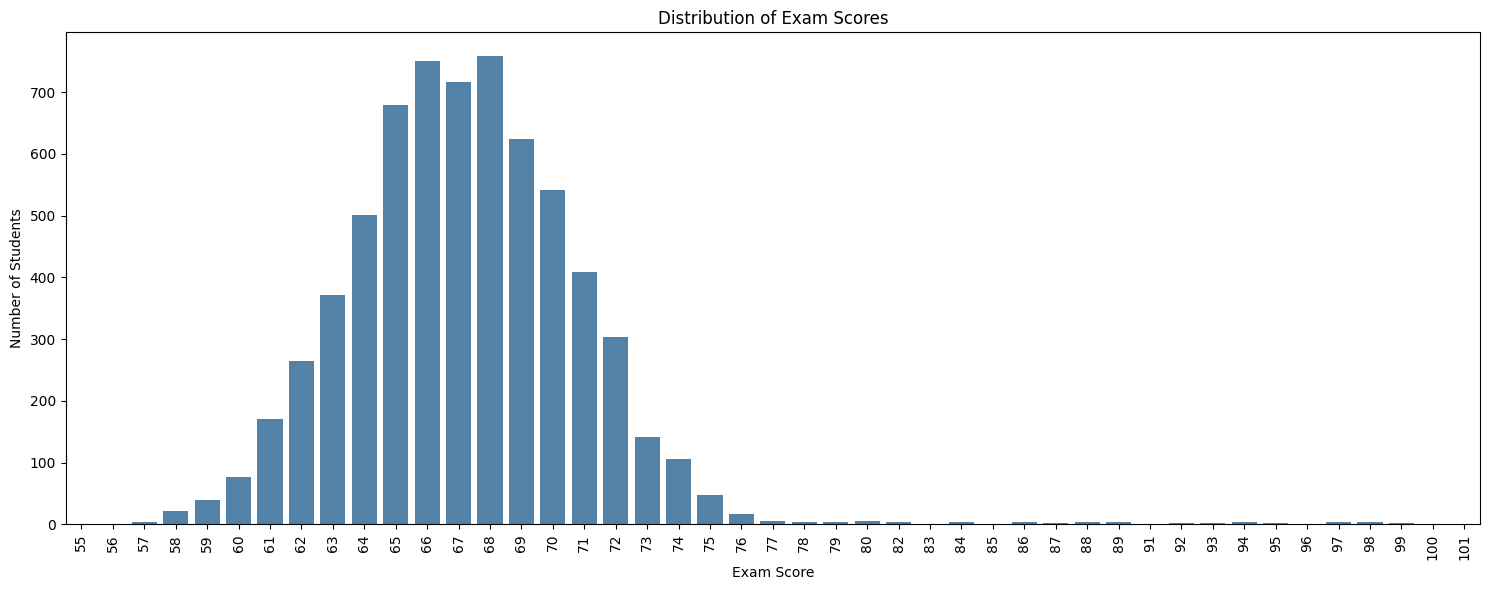

In [7]:

plt.figure(figsize=(15, 6))

sns.countplot(data=df, x="Exam_Score", color="steelblue")

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()



### Distribution of Study Hours

I will visualize the distribution of weekly study hours to understand students' study habits and identify unusually high or low values.

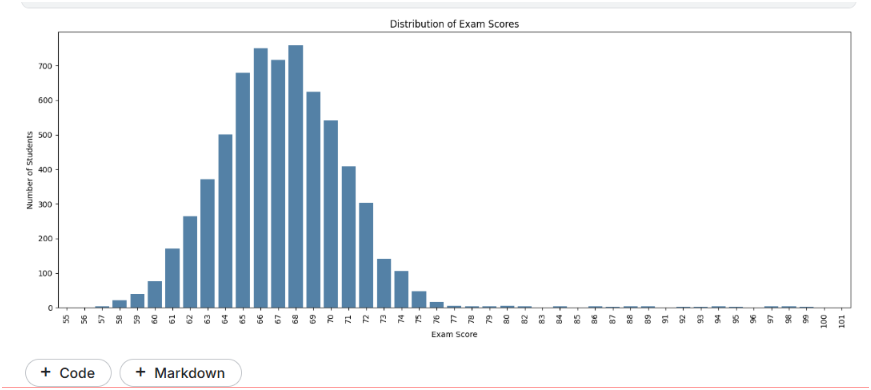

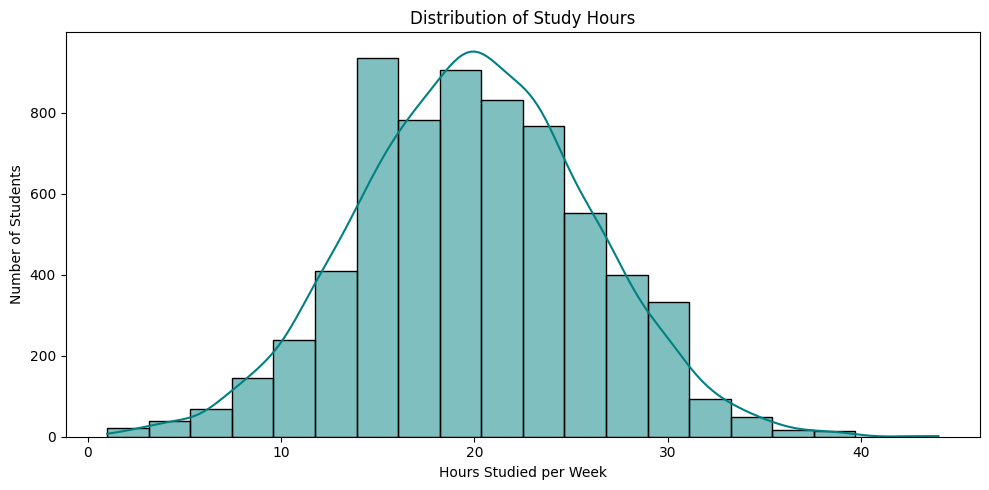

In [8]:

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Hours_Studied",
             bins=20, kde=True, color="teal")

plt.title("Distribution of Study Hours")
plt.xlabel("Hours Studied per Week")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()



### Parental Involvement and Exam Performance

I will compare exam scores across different parental involvement levels. This can help identify whether students with greater parental support tend to achieve different scores.


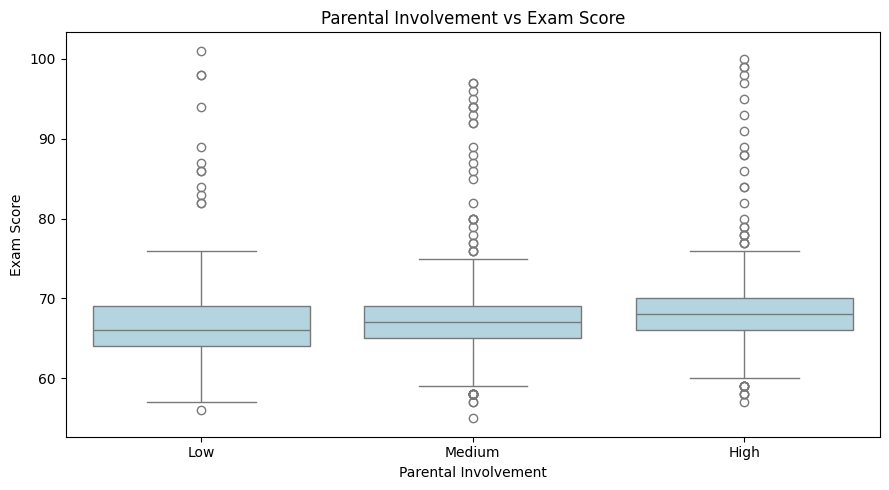

In [9]:

plt.figure(figsize=(9, 5))

sns.boxplot(data=df,
            x="Parental_Involvement",
            y="Exam_Score",
            order=["Low", "Medium", "High"],
            color="lightblue")

plt.title("Parental Involvement vs Exam Score")
plt.xlabel("Parental Involvement")
plt.ylabel("Exam Score")

plt.tight_layout()
plt.show()



### Correlation Analysis

I will calculate correlations between numerical variables to identify which features have stronger positive or negative relationships with Exam_Score.

This will help me understand potentially useful predictors.


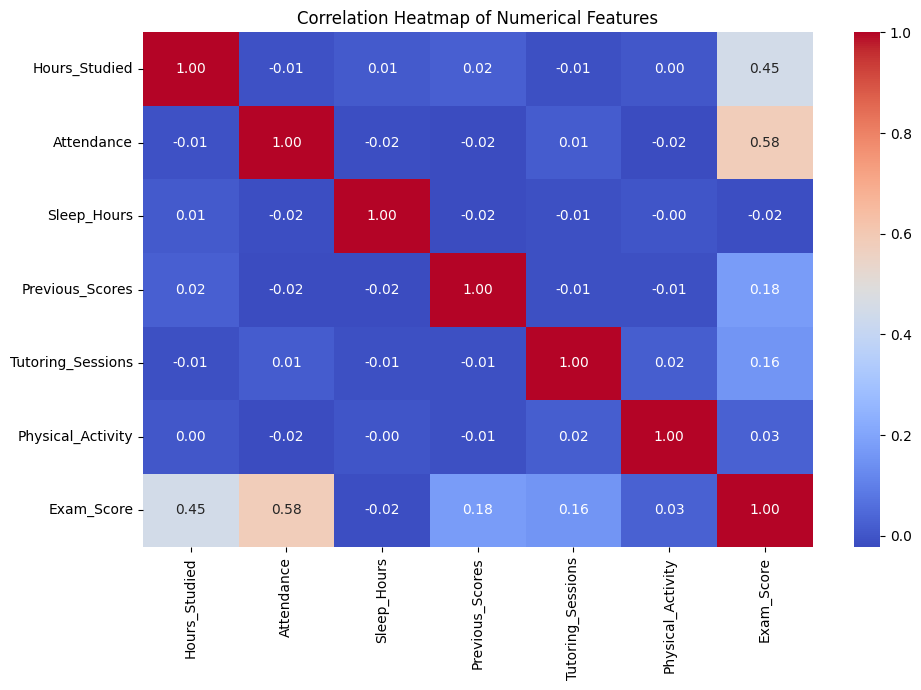

In [10]:

plt.figure(figsize=(10, 7))

numeric_data = df.select_dtypes(include="number")

sns.heatmap(numeric_data.corr(),
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()



### Correlation Analysis - Observations

Attendance (0.58) has the strongest positive correlation with Exam_Score, followed by Hours_Studied (0.45).

Previous_Scores (0.18) and Tutoring_Sessions (0.16) show weaker positive relationships.

Sleep_Hours and Physical_Activity have almost no linear correlation with Exam_Score.

These findings suggest that attendance and study hours may be important predictors of student performance.



## 2. Data Cleaning

### Checking Duplicate Records

I will check the dataset for duplicate rows and remove any exact duplicates.

Duplicate records may introduce unnecessary repetition and can affect model evaluation.


In [13]:

# Count duplicate rows
duplicates = df.duplicated().sum()

print("Duplicate rows found:", duplicates)

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)


Duplicate rows found: 0
Dataset shape after removing duplicates: (6607, 20)



### Missing Value Analysis

I will identify missing values in each column and visualize their frequency.

This analysis will help me decide how missing data should be handled without unnecessarily losing useful student records.


Missing Values Per Column:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


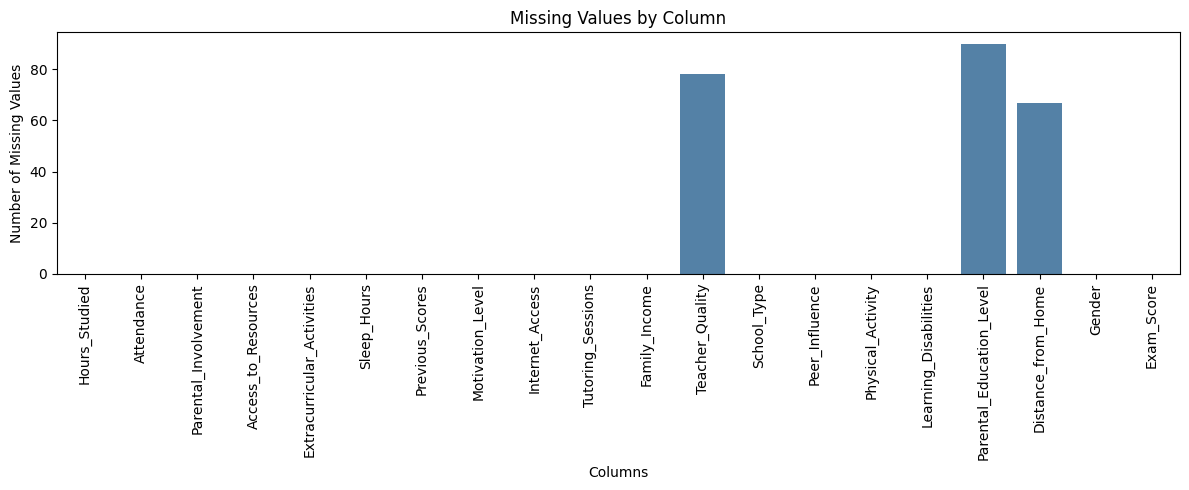

In [14]:

# Count missing values
missing_values = df.isnull().sum()

print("Missing Values Per Column:")
print(missing_values)

# Missing value visualization
plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing_values.index,
    y=missing_values.values,
    color="steelblue"
)

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()



### Identifying Unnecessary Columns

I reviewed the columns to identify identifiers or irrelevant information.

The dataset does not contain student IDs, names, or other obvious identifier columns. Therefore, I will retain all existing columns for now because they may contain useful information for predicting exam scores.


In [ ]:

print("Total columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns.tolist())

# No obvious useless columns to remove
columns_to_drop = []

df = df.drop(columns=columns_to_drop)

print("\nShape after column review:", df.shape)



### Missing Value Handling Decisions

I will retain all three columns containing missing values because they may provide useful information about student performance.

- Teacher_Quality: Fill missing values with the most frequent category.
- Parental_Education_Level: Fill missing values with the most frequent category.
- Distance_from_Home: Fill missing values with the most frequent category.

I will not remove rows with missing values because the missing entries represent a small portion of the dataset.

The actual imputation will be performed later using SimpleImputer, fitted only on the training data to prevent data leakage.



## 3. Feature Engineering

I will create two additional features from existing columns to help the model identify relationships that may not be obvious from individual features.

1. Study_Attendance_Interaction: Combines study hours and attendance percentage to represent how study effort and classroom participation interact.

2. Study_Sleep_Ratio: Measures the relationship between study hours and sleep duration. This may help identify different study and rest patterns.

Both features are created without using the target variable.


In [15]:

# Feature 1: Study and Attendance Interaction
df["Study_Attendance_Interaction"] = (
    df["Hours_Studied"] * df["Attendance"] / 100
)

# Feature 2: Study to Sleep Ratio
df["Study_Sleep_Ratio"] = (
    df["Hours_Studied"] / df["Sleep_Hours"]
)

# Display new features
display(df[[
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Study_Attendance_Interaction",
    "Study_Sleep_Ratio"
]].head())

print("Updated Dataset Shape:", df.shape)


,Hours_Studied,Attendance,Sleep_Hours,Study_Attendance_Interaction,Study_Sleep_Ratio
0,23,84,7,19.32,3.285714
1,19,64,8,12.16,2.375000
2,24,98,7,23.52,3.428571
3,29,89,8,25.81,3.625000
4,19,92,6,17.48,3.166667


Updated Dataset Shape: (6607, 22)



## 4. Feature and Target Selection

I will separate the dataset into input features (X) and the target variable (y).

Exam_Score is the target because the goal is to predict students' exam results using academic, personal, and environmental factors.


In [16]:

# Input features
X = df.drop(columns=["Exam_Score"])

# Target variable
y = df["Exam_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget Column:", y.name)


Features shape: (6607, 21)
Target shape: (6607,)

Target Column: Exam_Score


In [ ]:

## 5. Train-Test Split

I will divide the dataset into 80% training data and 20% testing data using random_state=42 for reproducibility.

Because Exam_Score is a continuous numerical target, this is a regression problem. Therefore, stratification and class proportions are not applicable. Instead, I will compare the target statistics between the two subsets.


In [17]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Compare target distributions
print("\nTraining Target Statistics:")
print(y_train.describe())

print("\nTesting Target Statistics:")
print(y_test.describe())


X_train: (5285, 21)
X_test: (1322, 21)
y_train: (5285,)
y_test: (1322,)

Training Target Statistics:
count    5285.000000
mean       67.215137
std         3.922228
min        56.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

Testing Target Statistics:
count    1322.000000
mean       67.317700
std         3.761087
min        55.000000
25%        65.000000
50%        67.000000
75%        70.000000
max        98.000000
Name: Exam_Score, dtype: float64



## 6. Data Preprocessing

### Identifying Feature Types

I will separate numerical and categorical features because they require different preprocessing methods.

Numerical features will be imputed using the median and scaled using StandardScaler. Categorical features will be imputed using the most frequent category and encoded using OneHotEncoder.


In [19]:

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
print(categorical_cols)

print("\nTotal Numerical:", len(numerical_cols))
print("Total Categorical:", len(categorical_cols))


Numerical Features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Study_Attendance_Interaction', 'Study_Sleep_Ratio']

Categorical Features:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Total Numerical: 8
Total Categorical: 13



### Creating Preprocessing Pipelines

I will create two preprocessing pipelines:

1. Numerical Pipeline: Replace missing numerical values with the training median, then standardize the features.
2. Categorical Pipeline: Replace missing categorical values with the most frequent training category, then apply one-hot encoding.

Using pipelines keeps the transformations organized and consistent.


In [20]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical pipeline
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipelines created successfully!")


Preprocessing pipelines created successfully!



### Applying Preprocessing Without Data Leakage

I will fit the preprocessing pipeline only on the training data using fit_transform().

The testing data will be processed using transform() without fitting again.

This prevents information from the test set from influencing the imputation values, scaling parameters, or encoding categories learned during training.


In [21]:

# Learn preprocessing from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply learned transformations to testing data
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert results to DataFrames
X_train = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Preprocessing completed successfully!")

print("\nProcessed Training Shape:", X_train.shape)
print("Processed Testing Shape:", X_test.shape)


Preprocessing completed successfully!

Processed Training Shape: (5285, 42)
Processed Testing Shape: (1322, 42)



## 7. Final Validation

I will verify the final shapes and ensure no missing values remain in the processed features or target.

The preprocessing was fitted only on training data, while the test data was transformed using the already fitted pipeline.

The final outputs are X_train, X_test, y_train, and y_test.


In [22]:

# Final dataset shapes
print("FINAL DATASET SHAPES")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check missing values
print("\nMISSING VALUES")
print("X_train:", X_train.isnull().sum().sum())
print("X_test:", X_test.isnull().sum().sum())
print("y_train:", y_train.isnull().sum())
print("y_test:", y_test.isnull().sum())

# Verify all features are numerical
print("\nAll features numerical:",
      all(pd.api.types.is_numeric_dtype(dtype)
          for dtype in X_train.dtypes))

# Confirm preprocessing has been fitted
from sklearn.utils.validation import check_is_fitted

check_is_fitted(preprocessor)

# Assertions
assert not X_train.isnull().values.any()
assert not X_test.isnull().values.any()
assert not y_train.isnull().any()
assert not y_test.isnull().any()

print("\nFinal validation passed!")
print("Test data was transformed without fitting.")


FINAL DATASET SHAPES
X_train: (5285, 42)
X_test: (1322, 42)
y_train: (5285,)
y_test: (1322,)

MISSING VALUES
X_train: 0
X_test: 0
y_train: 0
y_test: 0

All features numerical: True

Final validation passed!
Test data was transformed without fitting.
